<a href="https://colab.research.google.com/github/adilbashir017-ux/Data-Mining-and-Machine-Learning-/blob/main/Labs/Lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Braude College of Engineering - Data Mining & Machine Learning (61761)
# Lab 1: Working Environment, Data Inspection & Stratified Splitting

###1. Imports

In [36]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split

### 2. Session File Management & Data Loading

In [37]:
raw_data = load_wine(as_frame=True)
df = raw_data.frame

### Dataset Overview: The Wine Recognition Dataset

The **Wine dataset** is a classic multiclass classification dataset available directly via `sklearn.datasets.load_wine`.

* **Origin:** The dataset results from a chemical analysis of wines grown in the same region in Italy, derived from three different cultivars (classes 0, 1, and 2).
* **Samples:** 178 instances.
* **Features:** 13 continuous numerical attributes representing chemical and physical properties (e.g., `alcohol`, `malic_acid`, `ash`, `flavanoids`, `color_intensity`, `proline`).
* **Target:**
  * `class_label`: Multiclass target indicating the wine cultivar (זן) (0, 1, or 2).
  * `binary_target`: A transformed binary target (Class 0 vs. Others) used in this lab to simulate an imbalanced binary classification scenario.

In [38]:
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [39]:
df = df.rename(columns={"target": "class_label"})

In [40]:
df["binary_target"] = (df["class_label"] == 0).astype(int)

### 3. Basic Inspection Demonstrated by Instructor

In [41]:
print("=== First 5 Rows ===")
display(df.head())

=== First 5 Rows ===


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,class_label,binary_target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,1
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,1
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,1
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,1
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,1


In [42]:
print("\n=== Dataset Info ===")
df.info()


=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null

In [43]:
print("\n=== Basic Summary Statistics ===")
display(df.describe().T)


=== Basic Summary Statistics ===


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


### 4. Basic Train/Test Split (Demo - Without Stratification)

In [44]:
X_binary = df.drop(columns=["class_label", "binary_target"])
y_binary = df["binary_target"]

In [45]:
X_train_demo, X_test_demo, y_train_demo, y_test_demo = train_test_split(
    X_binary, y_binary, test_size=0.2, random_state=42
)

In [46]:
print("\n=== Demo: Original vs Test Proportions (Unstratified) ===")
print("Original:\n", y_binary.value_counts(normalize=True))
print("Test Set:\n", y_test_demo.value_counts(normalize=True))


=== Demo: Original vs Test Proportions (Unstratified) ===
Original:
 binary_target
0    0.668539
1    0.331461
Name: proportion, dtype: float64
Test Set:
 binary_target
0    0.611111
1    0.388889
Name: proportion, dtype: float64


### 5. Basic 2D Plot Demo

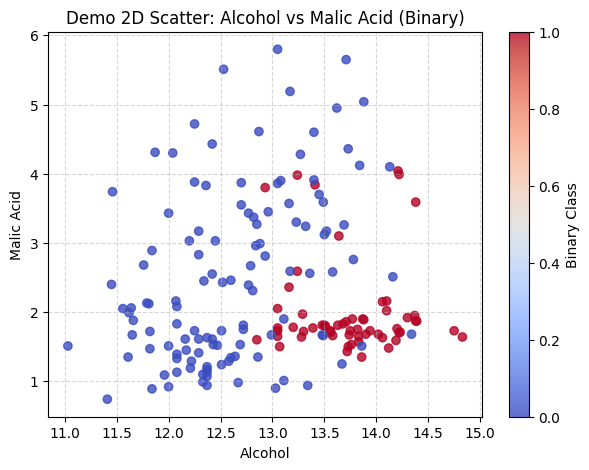

In [47]:
plt.figure(figsize=(7, 5))
plt.scatter(df["alcohol"], df["malic_acid"], c=df["binary_target"], cmap="coolwarm", alpha=0.8)
plt.xlabel("Alcohol")
plt.ylabel("Malic Acid")
plt.title("Demo 2D Scatter: Alcohol vs Malic Acid (Binary)")
plt.colorbar(label="Binary Class")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [48]:
# Task 1.1 - Display target columns

df[["class_label", "binary_target"]].head()
# Display the first five rows of the target columns.
# class_label represents three wine classes (0, 1, 2).
# binary_target represents Class 0 versus all other classes.


,class_label,binary_target
0,0,1
1,0,1
2,0,1
3,0,1
4,0,1


In [49]:
# Task 1.2 - Multi-class distribution (%)

print(df["class_label"].value_counts(normalize=True).sort_index() * 100)
# Calculate the percentage distribution of the three wine classes.
# Class 0: 33.15%, Class 1: 39.89%, Class 2: 26.97%.
# Class 1 has the highest number of samples.

class_label
0    33.146067
1    39.887640
2    26.966292
Name: proportion, dtype: float64


In [50]:
# Task 1.2 - Binary distribution (%)

print(df["binary_target"].value_counts(normalize=True).sort_index() * 100)
# Calculate the percentage distribution of the binary target.
# Class 0 contains 66.85% of the samples.
# Class 1 contains 33.15% of the samples.

binary_target
0    66.853933
1    33.146067
Name: proportion, dtype: float64


In [51]:
# Task 2.1 - Unstratified Split

X_train_un, X_test_un, y_train_un, y_test_un = train_test_split(
    X_binary, y_binary, test_size=0.2, random_state=42
)

print("Train samples:", len(X_train_un))
print("Test samples:", len(X_test_un))
# Randomly split the binary dataset into 80% training and 20% testing.
# The split produces 142 training samples and 36 testing samples.
# Class proportions are not preserved by this method.

Train samples: 142
Test samples: 36


In [52]:
# Task 2.2 - Stratified Split

X_train_str, X_test_str, y_train_str, y_test_str = train_test_split(
    X_binary, y_binary,
    test_size=0.2,
    random_state=42,
    stratify=y_binary
)

print("Train samples:", len(X_train_str))
print("Test samples:", len(X_test_str))
# Split the binary dataset into 80% training and 20% testing.
# Stratification preserves approximately the original class proportions.
# The split produces 142 training samples and 36 testing samples.

Train samples: 142
Test samples: 36


In [53]:
# Task 2.3 - Compare Class Distributions

comparison = pd.DataFrame({
    "Original": y_binary.value_counts(normalize=True) * 100,
    "Unstratified Test": y_test_un.value_counts(normalize=True) * 100,
    "Stratified Test": y_test_str.value_counts(normalize=True) * 100
})

print(comparison.sort_index().round(2))
# Compare class distributions in the original and test datasets.
# The unstratified split changes the original class proportions.
# The stratified split maintains proportions closer to the original.

               Original  Unstratified Test  Stratified Test
binary_target                                              
0                 66.85              61.11            66.67
1                 33.15              38.89            33.33


In [54]:
# Task 3.1 - Multi-Class Stratified Split

X_multi = df.drop(columns=["class_label", "binary_target"])
y_multi = df["class_label"]

X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi, y_multi,
    test_size=0.3,
    random_state=42,
    stratify=y_multi
)

print("Train samples:", len(X_train_multi))
print("Test samples:", len(X_test_multi))
# Perform a stratified split using the three original wine classes.
# Split the dataset into 70% training and 30% testing.
# The result contains 124 training samples and 54 testing samples.

Train samples: 124
Test samples: 54


In [55]:
# Task 3.2 - Verify Multi-Class Stratification

comparison_multi = pd.DataFrame({
    "Original": y_multi.value_counts(normalize=True) * 100,
    "Train": y_train_multi.value_counts(normalize=True) * 100,
    "Test": y_test_multi.value_counts(normalize=True) * 100
})

print(comparison_multi.sort_index().round(2))

# Verify that differences are within 1 percentage point
diff = comparison_multi[["Train", "Test"]].sub(
    comparison_multi["Original"], axis=0
).abs()

print("\nStratification verified for each class:")
print((diff <= 1).all(axis=1))
# Compare the class proportions in the original, training, and test sets.
# Verify that each class differs by no more than one percentage point.
# All three classes pass the verification, confirming a successful split.

             Original  Train   Test
class_label                        
0               33.15  33.06  33.33
1               39.89  40.32  38.89
2               26.97  26.61  27.78

Stratification verified for each class:
class_label
1    True
0    True
2    True
dtype: bool


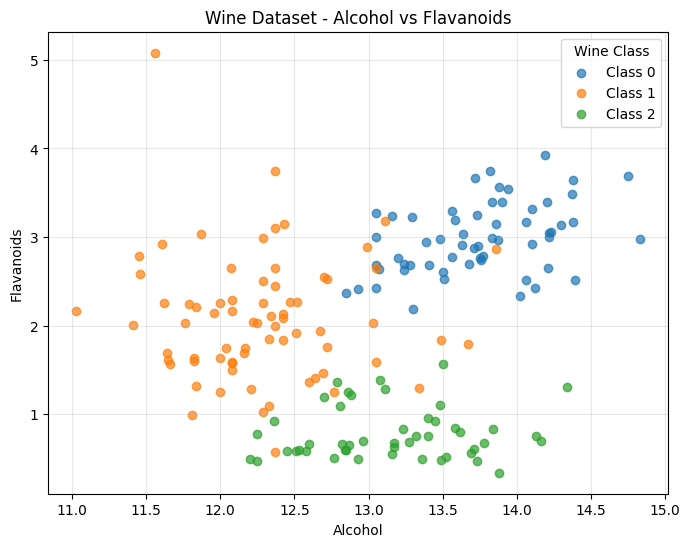

In [56]:
# Task 4 - 2D Feature Space Visualization

plt.figure(figsize=(8, 6))

for class_id in sorted(df["class_label"].unique()):
    subset = df[df["class_label"] == class_id]

    plt.scatter(
        subset["alcohol"],
        subset["flavanoids"],
        label=f"Class {class_id}",
        alpha=0.7
    )

plt.xlabel("Alcohol")
plt.ylabel("Flavanoids")
plt.title("Wine Dataset - Alcohol vs Flavanoids")

plt.legend(title="Wine Class")
plt.grid(True, alpha=0.3)

plt.show()
# Visualize the wine dataset using a two-dimensional scatter plot.
# The X-axis represents alcohol, and the Y-axis represents flavanoids.
# Each wine class is displayed using a different color.
# The plot shows partial separation and some overlap between classes.